The function is modeled by a multivarable Gaussian as 

$$p(\mathbf{f} \, \lvert\, \mathbf{X}) = \mathcal{N}(\mathbf{f} \, \lvert\, \boldsymbol\mu, \mathbf{K})$$

where $\mathbf{f} = (f(\mathbf{x}_1),...,f(\mathbf{x}_n))$, $\boldsymbol\mu = (m(\mathbf{x}_1),...,m(\mathbf{x}_n))$ and $K_{ij} = \kappa(\mathbf{x}_i,\mathbf{x}_j)$. $m$ is the mean function and it is common to use $m(\mathbf{x}) = 0$ as GPs are flexible enough to model the mean arbitrarily well. $\kappa$ is a positive definite *kernel function* or *covariance function*. Thus, a Gaussian process is a distribution over functions whose shape (smoothness, ...) is defined by $\mathbf{K}$. If points $\mathbf{x}_i$ and $\mathbf{x}_j$ are considered to be similar by the kernel the function values at these points, $f(\mathbf{x}_i)$ and $f(\mathbf{x}_j)$, can be expected to be similar too. 

So, we have observations, and we have estimated functions $\mathbf{f}$ with these observations. Now say we have some new points $\mathbf{X}_*$ where we want to predict $f(\mathbf{X}_*)$.

<img src="https://github.com/jwangjie/Gaussian-Process-be-comfortable-using-it/blob/master/img/mvn.png?raw=1" width="250"/> 

## Implementation with NumPy

Here, we will use the squared exponential kernel, also known as Gaussian kernel or RBF kernel:

## $$ k(x,y) =  \sigma_f^2 exp(-\frac{d^2}{2\ell^2}) $$

## $$ d= || x-y|| $$

The length parameter $\ell$ controls the smoothness of the function and $\sigma_f$ the vertical variation. For simplicity, we use the same length parameter $\ell$ for all input dimensions (isotropic kernel). 

In [1]:
import numpy as np

def kernel(X1, X2, l=1.0, sigma_f=1.0):
    """
    Isotropic squared exponential kernel.
    
    Args:
        X1: Array of m points (m x d).
        X2: Array of n points (n x d).

    Returns:
        (m x n) matrix.
    """
    sqdist = np.sum(X1**2, 1).reshape(-1, 1) + np.sum(X2**2, 1) - 2 * np.dot(X1, X2.T)
    return sigma_f**2 * np.exp(-0.5 / l**2 * sqdist)

There are many other kernels that can be used for Gaussian processes. See \[3\] for a detailed reference or the scikit-learn documentation for [some examples](http://scikit-learn.org/stable/modules/gaussian_process.html#gp-kernels).

In [2]:

from gaussian_processes_util import plot_gp

# Finite number of points
X = np.arange(-5, 5, 0.2).reshape(-1, 1)

# Mean and covariance of the prior
mu = np.zeros(X.shape)
cov = kernel(X, X, 1,5)

# Draw three samples from the prior
samples = np.random.multivariate_normal(mu.ravel(), cov, 20)

# Plot GP mean, uncertainty region and samples 
plot_gp(mu, cov, X, samples=samples)

ModuleNotFoundError: No module named 'gaussian_processes_util'

The `plot_gp` function is defined [here](gaussian_processes_util.py).

### Prediction from noise-free training data

To compute the sufficient statistics i.e. mean and covariance of the posterior we implement Equations $(7)$ and $(8)$.

In [7]:
from numpy.linalg import inv

def posterior(X_s, X_train, Y_train, l=1.0, sigma_f=1.0, sigma_y=1e-8):
    """
    Computes the suffifient statistics of the posterior distribution 
    from m training data X_train and Y_train and n new inputs X_s.
    
    Args:
        X_s: New input locations (n x d).
        X_train: Training locations (m x d).
        Y_train: Training targets (m x 1).
        l: Kernel length parameter.
        sigma_f: Kernel vertical variation parameter.
        sigma_y: Noise parameter.
    
    Returns:
        Posterior mean vector (n x d) and covariance matrix (n x n).
    """
    K = kernel(X_train, X_train, l, sigma_f) + sigma_y**2 * np.eye(len(X_train))
    K_s = kernel(X_train, X_s, l, sigma_f)
    K_ss = kernel(X_s, X_s, l, sigma_f) + 1e-8 * np.eye(len(X_s))
    K_inv = inv(K)
    
    # Equation (7)
    mu_s = K_s.T.dot(K_inv).dot(Y_train)

    # Equation (8)
    cov_s = K_ss - K_s.T.dot(K_inv).dot(K_s)
    
    return mu_s, cov_s

and apply them to noise-free training data `X_train` and `Y_train`. The following example draws three samples from the posterior and plots them along with the mean, uncertainty region and training data. In a noise-free model, variance at the training points is zero and all random functions drawn from the posterior go through the trainig points. 

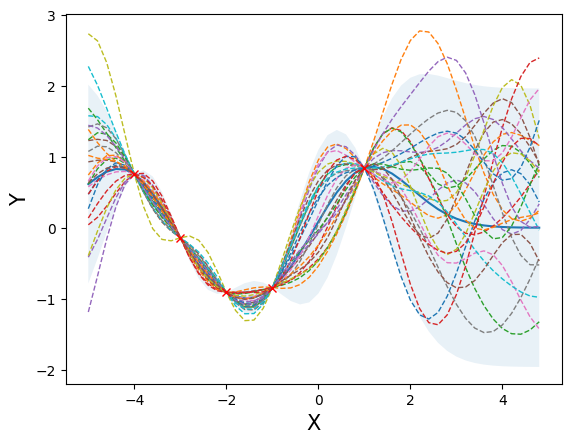

In [8]:
# Noise free training data
X_train = np.array([-4, -3, -2, -1, 1]).reshape(-1, 1)
Y_train = np.sin(X_train)

# Compute mean and covariance of the posterior distribution
mu_s, cov_s = posterior(X, X_train, Y_train, l=1, sigma_f = 1)

samples = np.random.multivariate_normal(mu_s.ravel(), cov_s, 25)
plot_gp(mu_s, cov_s, X, X_train=X_train, Y_train=Y_train, samples=samples)

### Prediction from noisy training data

If some noise is included in the model, training points are only approximated and the variance at the training points is non-zero.

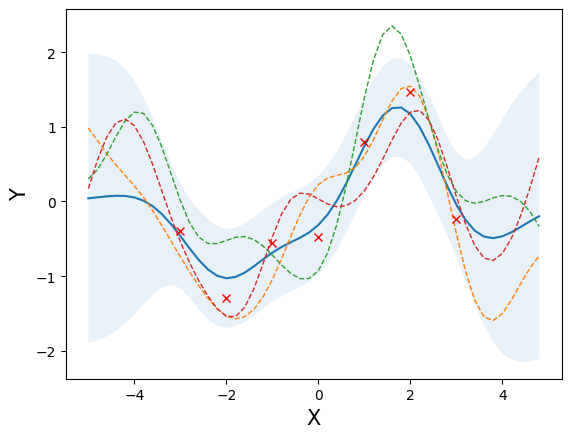

In [17]:
noise = 0.4

# Noisy training data
X_train = np.arange(-3, 4, 1).reshape(-1, 1)
Y_train = np.sin(X_train) + noise * np.random.randn(*X_train.shape)

# Compute mean and covariance of the posterior distribution
mu_s, cov_s = posterior(X, X_train, Y_train,  l=1, sigma_f = 1, sigma_y=noise)

samples = np.random.multivariate_normal(mu_s.ravel(), cov_s, 3)
plot_gp(mu_s, cov_s, X, X_train=X_train, Y_train=Y_train, samples=samples)

### Effect of kernel parameters and noise parameter

The following example shows the effect of kernel parameters $l$ and $\sigma_f$ as well as the noise parameter $\sigma_y$. Higher $l$ values lead to smoother functions and therefore to coarser approximations of the training data. Lower $l$ values make functions more wiggly with wide uncertainty regions between training data points. $\sigma_f$ controls the vertical variation of functions drawn from the GP. This can be seen by the wide uncertainty regions outside the training data region in the right figure of the second row. $\sigma_y$ represents the amount of noise in the training data. Higher $\sigma_y$ values make more coarse approximations which avoids overfitting to noisy data.

## $$ k(x,y) =  \sigma_f^2 exp(-\frac{d^2}{2\ell^2})+ \sigma_y$$

## $$ d= || x-y|| $$

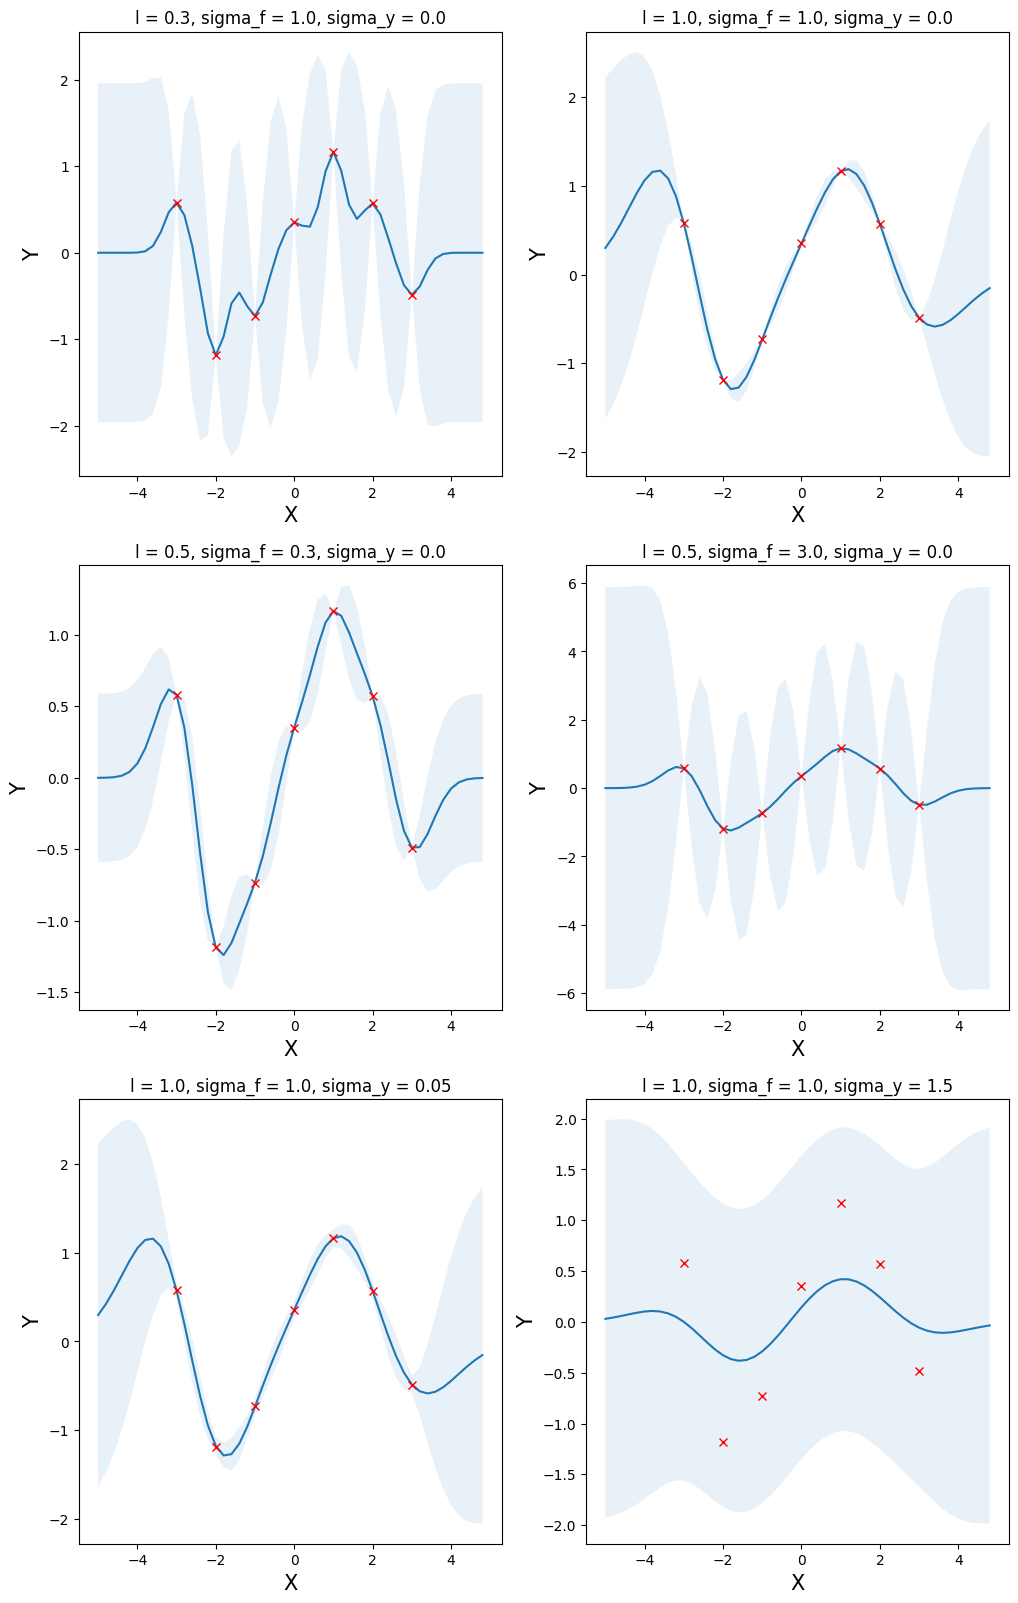

In [9]:
import matplotlib.pyplot as plt

params = [
    (0.3, 1.0, 0.),
    (1.0, 1.0, 0.),
    (0.5, 0.3, 0.0),
    (0.5, 3.0, 0.0),
    (1.0, 1.0, 0.05),
    (1.0, 1.0, 1.5),
]

plt.figure(figsize=(12, 8))

for i, (l, sigma_f, sigma_y) in enumerate(params):
    mu_s, cov_s = posterior(X, X_train, Y_train, l=l, 
                            sigma_f=sigma_f, 
                            sigma_y=sigma_y)
    plt.subplot(3, 2, i + 1)
    plt.subplots_adjust(top=2)
    plt.title(f'l = {l}, sigma_f = {sigma_f}, sigma_y = {sigma_y}')
    plot_gp(mu_s, cov_s, X, X_train=X_train, Y_train=Y_train)